In [44]:
!pip install -q kaggle tensorflow matplotlib  seaborn

In [46]:
from google.colab import files
files.upload()

KeyboardInterrupt: 

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d puneet6060/intel-image-classification

In [48]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

In [49]:
!unzip intel-image-classification.zip -d /content/my_extracted_folder


Archive:  intel-image-classification.zip
replace /content/my_extracted_folder/seg_pred/seg_pred/10004.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [50]:
!find . -maxdepth 3 -type d | head -50

.
./.config
./.config/logs
./.config/logs/2026.09.30
./.config/configurations
./my_extracted_folder
./my_extracted_folder/seg_pred
./my_extracted_folder/seg_pred/seg_pred
./my_extracted_folder/seg_train
./my_extracted_folder/seg_train/seg_train
./my_extracted_folder/seg_test
./my_extracted_folder/seg_test/seg_test
./sample_data


In [51]:
train_dir =r'/content/my_extracted_folder/seg_train/seg_train'
test_dir =r'/content/my_extracted_folder/seg_test/seg_test'

In [52]:
classes = sorted(os.listdir(train_dir))

print(classes)
print("Number of classes:", len(classes))

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of classes: 6


In [54]:
# Image count
for class_name in classes :
  class_path = os.path.join(train_dir,class_name )
  count= len(os.listdir(class_path))
  print(class_name ,":", count)

buildings : 2191
forest : 2271
glacier : 2404
mountain : 2512
sea : 2274
street : 2382


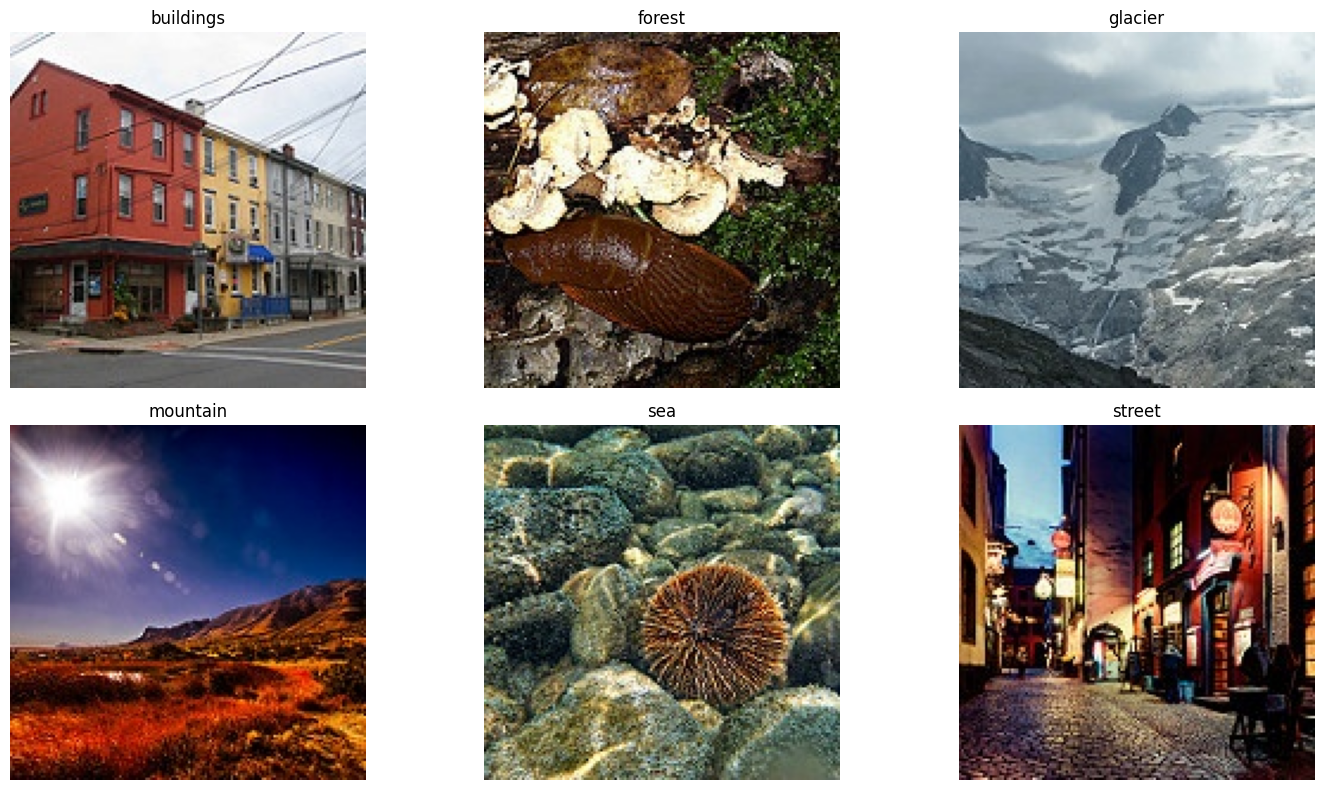

In [55]:
plt.figure(figsize=(15, 8))

for i, class_name in enumerate(classes):

    class_path = os.path.join(train_dir, class_name)

    image_name = os.listdir(class_path)[0]

    image_path = os.path.join(class_path, image_name)

    image = plt.imread(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Image Preprocessing

      224X224 is a standard input size for imagenet-pretrained vision  model and is directly supported by mobileNetv2

In [56]:
img_size=(224,224)
batch_size=32

In [57]:
# Data Generator
train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)
train_datagen

In [58]:
train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    subset="training",
    shuffle=True
)

Found 11230 images belonging to 6 classes.


In [59]:
# validation data
validation_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)

Found 2804 images belonging to 6 classes.


In [60]:
print(train_data.class_indices)

{'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


In [61]:
# load pretraind model --. MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [62]:
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
output = Dense(6, activation="softmax")(x)


In [63]:
model = Model(inputs=base_model.input, outputs=output)

In [64]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 2,388,614 (9.11 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [65]:
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [67]:
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
history= model.fit(train_data,validation_data=validation_data,epochs=2)

Epoch 1/2
351/351 ━━━━━━━━━━━━━━━━━━━━ 310s 704ms/step - accuracy: 0.8403 - loss: 0.4399 - val_accuracy: 0.8288 - val_loss: 0.5135
Epoch 2/2
351/351 ━━━━━━━━━━━━━━━━━━━━ 198s 563ms/step - accuracy: 0.9069 - loss: 0.2662 - val_accuracy: 0.8884 - val_loss: 0.3629


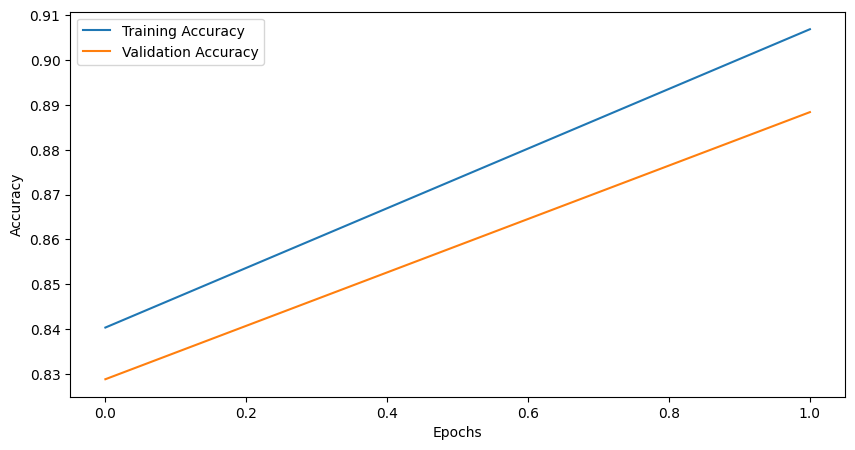

In [68]:
# Plot Accuracy
plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

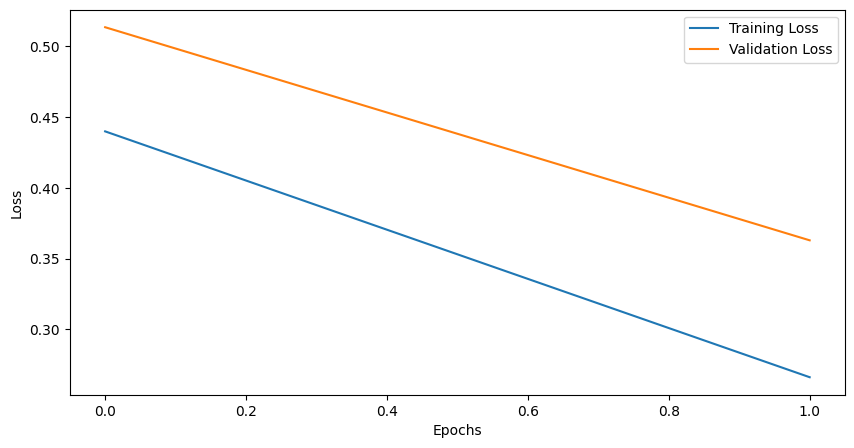

In [69]:
# plot loss
plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [70]:
# Test Dataset
test_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input)
test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    shuffle=False
)

Found 3000 images belonging to 6 classes.


In [71]:
# evaluate the model
test_loss, test_accuracy = model.evaluate(test_data)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 11s 120ms/step - accuracy: 0.8983 - loss: 0.3152
Test Loss: 0.3152
Test Accuracy: 89.83%


In [73]:
# confusion Matrix
predictions = model.predict(test_data)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_data.classes

94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step


Text(0.5, 1.0, 'Confusion Matrix')

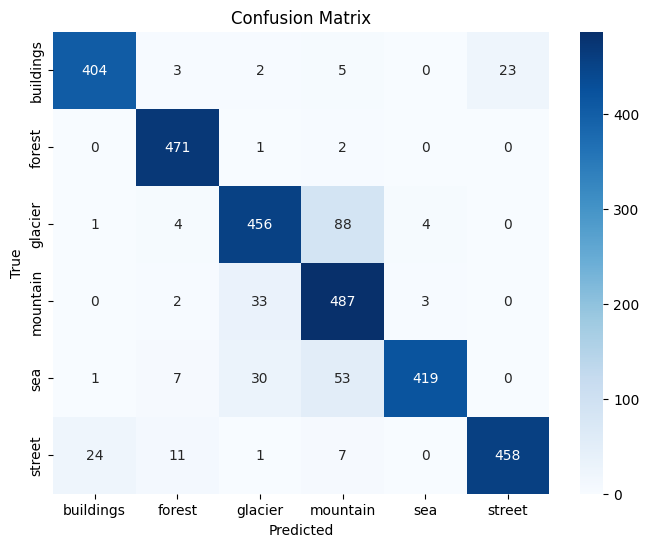

In [74]:
from sklearn.metrics import confusion_matrix, classification_report
cm = confusion_matrix(true_classes, predicted_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")

In [75]:
# classification report
from sklearn.metrics import classification_report
class_report = classification_report(true_classes, predicted_classes, target_names=classes)
print("Classification Report:\n", class_report)

Classification Report:
               precision    recall  f1-score   support

   buildings       0.94      0.92      0.93       437
      forest       0.95      0.99      0.97       474
     glacier       0.87      0.82      0.85       553
    mountain       0.76      0.93      0.83       525
         sea       0.98      0.82      0.90       510
      street       0.95      0.91      0.93       501

    accuracy                           0.90      3000
   macro avg       0.91      0.90      0.90      3000
weighted avg       0.91      0.90      0.90      3000



In [77]:
# predict a single image
from tensorflow.keras.utils import load_img, img_to_array
image_path= "/content/my_extracted_folder/seg_test/seg_test/sea/20072.jpg"
img = load_img(image_path, target_size=img_size)
img_array=img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)
prediction = model.predict(img_array)

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


In [78]:
predicted_class_index = np.argmax(prediction)
predicted_class = list(train_data.class_indices.keys())[predicted_class_index]
print("Predicted Class:", predicted_class)

Predicted Class: sea


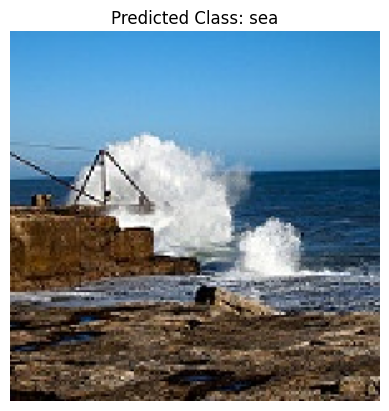

In [79]:
# display prediction
plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted Class: {predicted_class}")
plt.axis('off')
plt.show()

In [80]:
!pip install -q gradio

In [81]:
import tensorflow as tf
import numpy as np
import gradio as gr

# The model object is already available in the kernel from previous cells
# model = tf.keras.models.load_model(
#     "/content/intel_mobilenetv2_model.keras"
# )

classes = [
    "buildings",
    "forest",
    "glacier",
    "mountain",
    "sea",
    "street"
]

IMG_SIZE = (224, 224)

In [82]:
def predict_image(image):

    # Resize image
    image = image.resize(IMG_SIZE)

    # Convert image to NumPy array
    image = np.array(image)

    # Add batch dimension
    image = np.expand_dims(image, axis=0)

    # MobileNetV2 preprocessing
    image = tf.keras.applications.mobilenet_v2.preprocess_input(
        image
    )

    # Prediction
    prediction = model.predict(image, verbose=0)[0]

    # Get class
    predicted_index = np.argmax(prediction)

    predicted_class = classes[predicted_index]

    confidence = float(prediction[predicted_index])

    return {
        classes[i]: float(prediction[i])
        for i in range(len(classes))
    }

In [83]:
demo = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(
        type="pil",
        label="Upload Scene Image"
    ),
    outputs=gr.Label(
        num_top_classes=6,
        label="Prediction"
    ),
    title="Intel Scene Classification",
    description="Upload an image to classify it into one of six scene categories using MobileNetV2 Transfer Learning."
)

In [84]:
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8bf4954019c931ac60.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
